# Practical 10 — Validation, Evaluation and Deployment of the Integrated Intelligent System

**Course:** Computational Intelligence Laboratory (CELBC710)  
**Aim:** Validate and evaluate the integrated Practical 9 system, test input reliability and responsible-use limitations, and demonstrate deployment through a small Streamlit interface.

**Approach:** Reuse the exact saved LSTM encoder, Random Forest, preprocessing objects, thresholds and rule policy from Practical 9. This practical validates and packages the existing system; it does not silently retrain a new model.

> **Important:** The model performs same-day Flood/No Flood classification using a seven-day window ending on the day being classified. It is not a next-day forecast or a validated public warning service.

## 1. Load packages and locate the Practical 9 artifacts

If the files are not present beside this notebook, the setup cell asks for the complete Practical 10 ZIP. Keep the notebook, `model_artifacts`, `input_data`, and `system_core.py` together.

In [1]:
from pathlib import Path
import sys, json, zipfile, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

ROOT = Path.cwd()
def find_package_root(start):
    candidates = [start, start / "practical10_package", start / "CIL_Practical_10_Package"]
    for candidate in candidates:
        if (candidate / "model_artifacts" / "task9_system_metadata.json").exists():
            return candidate
    # A notebook opened separately in Colab may not have its supporting files yet.
    try:
        from google.colab import files as colab_files
        print("Upload CIL_Practical_10_Package.zip to load the saved models and dataset.")
        uploaded = colab_files.upload()
        zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
        if zip_name:
            extract_dir = start / "practical10_package_extracted"
            extract_dir.mkdir(exist_ok=True)
            with zipfile.ZipFile(start / zip_name) as zf:
                zf.extractall(extract_dir)
            for candidate in [extract_dir, *extract_dir.iterdir()]:
                if candidate.is_dir() and (candidate / "model_artifacts" / "task9_system_metadata.json").exists():
                    return candidate
    except Exception:
        pass
    raise FileNotFoundError("Could not find model_artifacts/task9_system_metadata.json. Extract the Practical 10 package beside this notebook.")

ROOT = find_package_root(ROOT)
sys.path.insert(0, str(ROOT))
RESULT_DIR = ROOT / "practical10_results"
RESULT_DIR.mkdir(exist_ok=True)
DATA_PATH = ROOT / "input_data" / "flood_dataset.csv"
PREDICTIONS_PATH = ROOT / "validation_data_task9_predictions.csv"
ARTIFACT_DIR = ROOT / "model_artifacts"

from system_core import IntegratedFloodSystem, ENVIRONMENTAL_FEATURES
system = IntegratedFloodSystem(ARTIFACT_DIR)
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
predictions = pd.read_csv(PREDICTIONS_PATH)
print("Package root:", ROOT)
print("Dataset shape:", df.shape)
print("Saved Practical 9 test predictions:", predictions.shape)
print("Window length:", system.window_days)
print("LSTM device:", system.device)
print("Saved model artifacts loaded: PASS")

Package root: /mnt/data/practical10_package
Dataset shape: (1364, 25)
Saved Practical 9 test predictions: (204, 11)
Window length: 7
LSTM device: cpu
Saved model artifacts loaded: PASS


## 2. Validate the source data

Check date integrity, target labels and class balance before trusting downstream results. Duplicate dates or missing daily intervals are reported rather than silently removed.

In [2]:
required = {"date", "flood_event", *ENVIRONMENTAL_FEATURES}
missing_columns = sorted(required - set(df.columns))
date_sorted = df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)
date_gaps = date_sorted["date"].diff().dropna().dt.days
checks = [
    {"Check": "Required columns present", "Result": "PASS" if not missing_columns else "FAIL", "Detail": "None missing" if not missing_columns else ", ".join(missing_columns)},
    {"Check": "Duplicate dates", "Result": "PASS" if not date_sorted["date"].duplicated().any() else "REVIEW", "Detail": int(date_sorted["date"].duplicated().sum())},
    {"Check": "Consecutive daily timeline", "Result": "PASS" if len(date_gaps) and (date_gaps == 1).all() else "REVIEW", "Detail": f"{int((date_gaps != 1).sum())} non-daily intervals"},
    {"Check": "Target labels are binary", "Result": "PASS" if set(pd.to_numeric(df["flood_event"], errors="coerce").dropna().unique()).issubset({0,1}) else "FAIL", "Detail": "Expected 0=No Flood, 1=Flood"},
]
validation_table = pd.DataFrame(checks)
display(validation_table)
print("Date range:", date_sorted["date"].min().date(), "to", date_sorted["date"].max().date())
display(df["flood_event"].value_counts(dropna=False).rename(index={0:"No Flood",1:"Flood"}).to_frame("Rows"))
validation_table.to_csv(RESULT_DIR / "task10_source_validation.csv", index=False)

if missing_columns:
    raise ValueError(f"Dataset missing columns: {missing_columns}")

,Check,Result,Detail
0,Required columns present,PASS,None missing
1,Duplicate dates,PASS,0
2,Consecutive daily timeline,PASS,0 non-daily intervals
3,Target labels are binary,PASS,"Expected 0=No Flood, 1=Flood"


Date range: 2022-01-01 to 2025-09-25


,Rows
flood_event,
No Flood,888
Flood,476


## 3. Re-evaluate the held-out test outputs

These predictions were produced by Practical 9 on its chronological test period. Practical 10 recomputes the main metrics and error counts from the saved predictions; it does not use the test labels to retune the model.

,Test observations,Accuracy,Balanced accuracy,Flood precision,Flood recall,Flood F1-score,False positives,False negatives
0,204,0.8971,0.8849,0.8904,0.8333,0.8609,8,13


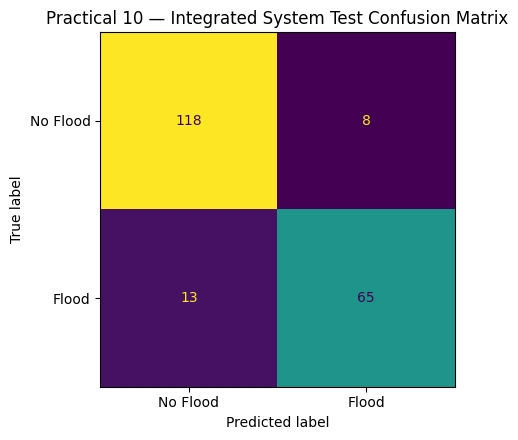

,date,Actual,Integrated prediction,Integrated probability,AI advisory,Error type
10,2025-03-16,Flood,No Flood,0.4781,LOW RISK,False negative (missed Flood)
19,2025-03-25,No Flood,Flood,0.6419,FLOOD WARNING,False positive (false alarm)
41,2025-04-16,Flood,No Flood,0.2337,LOW RISK,False negative (missed Flood)
43,2025-04-18,Flood,No Flood,0.1503,LOW RISK,False negative (missed Flood)
47,2025-04-22,Flood,No Flood,0.1318,LOW RISK,False negative (missed Flood)
50,2025-04-25,Flood,No Flood,0.3595,LOW RISK,False negative (missed Flood)
62,2025-05-07,Flood,No Flood,0.1221,MONITOR,False negative (missed Flood)
65,2025-05-10,No Flood,Flood,0.5232,FLOOD WATCH,False positive (false alarm)
71,2025-05-16,Flood,No Flood,0.2453,LOW RISK,False negative (missed Flood)
74,2025-05-19,No Flood,Flood,0.8041,FLOOD WARNING,False positive (false alarm)


Total misclassified cases: 21


In [3]:
actual = predictions["Actual"].map({"No Flood": 0, "Flood": 1}).to_numpy()
predicted = predictions["Integrated prediction"].map({"No Flood": 0, "Flood": 1}).to_numpy()
probability = predictions["Integrated probability"].to_numpy(dtype=float)
metrics = pd.DataFrame([{
    "Test observations": len(actual),
    "Accuracy": accuracy_score(actual, predicted),
    "Balanced accuracy": balanced_accuracy_score(actual, predicted),
    "Flood precision": precision_score(actual, predicted, zero_division=0),
    "Flood recall": recall_score(actual, predicted, zero_division=0),
    "Flood F1-score": f1_score(actual, predicted, zero_division=0),
    "False positives": int(((actual == 0) & (predicted == 1)).sum()),
    "False negatives": int(((actual == 1) & (predicted == 0)).sum()),
}])
display(metrics.round(4))
metrics.to_csv(RESULT_DIR / "task10_integrated_test_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(actual, predicted, labels=[0,1]), display_labels=["No Flood", "Flood"]).plot(ax=ax, colorbar=False, values_format="d")
ax.set_title("Practical 10 — Integrated System Test Confusion Matrix")
fig.tight_layout(); fig.savefig(RESULT_DIR / "task10_confusion_matrix.png", dpi=160); plt.show()

error_rows = predictions.loc[actual != predicted].copy()
error_rows["Error type"] = np.where(
    (error_rows["Actual"] == "Flood") & (error_rows["Integrated prediction"] == "No Flood"),
    "False negative (missed Flood)", "False positive (false alarm)")
display(error_rows[["date", "Actual", "Integrated prediction", "Integrated probability", "AI advisory", "Error type"]].head(15).round(4))
error_rows.to_csv(RESULT_DIR / "task10_misclassified_cases.csv", index=False)
print("Total misclassified cases:", len(error_rows))

## 4. Inspect advisory behavior and error types

The rule engine produces a readable advisory, but a watch or warning is not an official emergency alert. The table below checks how often each advisory occurred in the saved test period.

,AI advisory,Test cases
0,LOW RISK,125
1,FLOOD WARNING,72
2,MONITOR,6
3,FLOOD WATCH,1


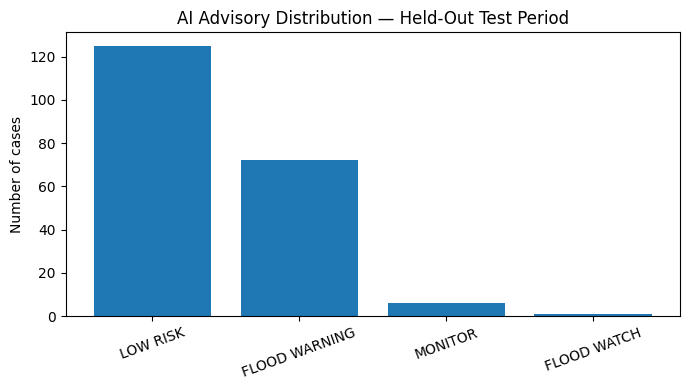

,Month,Rows,Flood cases,Accuracy,Flood recall
0,2025-03,26,9,0.923,0.889
1,2025-04,30,13,0.867,0.692
2,2025-05,31,12,0.839,0.750
3,2025-06,30,11,1.000,1.000
4,2025-07,31,8,0.935,1.000
5,2025-08,31,13,0.871,0.769
6,2025-09,25,12,0.840,0.833


In [4]:
advisory_counts = predictions["AI advisory"].value_counts().rename_axis("AI advisory").reset_index(name="Test cases")
display(advisory_counts)
advisory_counts.to_csv(RESULT_DIR / "task10_advisory_counts.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(advisory_counts["AI advisory"], advisory_counts["Test cases"])
ax.set_title("AI Advisory Distribution — Held-Out Test Period")
ax.set_ylabel("Number of cases")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout(); fig.savefig(RESULT_DIR / "task10_advisory_distribution.png", dpi=160); plt.show()

# Calendar-month slices are a basic temporal stability check, not a demographic fairness audit.
predictions["month"] = pd.to_datetime(predictions["date"]).dt.to_period("M").astype(str)
monthly_rows = []
for month, group in predictions.groupby("month"):
    yt = group["Actual"].map({"No Flood":0,"Flood":1}).to_numpy()
    yp = group["Integrated prediction"].map({"No Flood":0,"Flood":1}).to_numpy()
    monthly_rows.append({"Month":month, "Rows":len(group), "Flood cases":int((yt==1).sum()),
                         "Accuracy":accuracy_score(yt,yp),
                         "Flood recall":recall_score(yt,yp,zero_division=0) if len(set(yt))>1 else np.nan})
monthly_metrics = pd.DataFrame(monthly_rows)
display(monthly_metrics.round(3))
monthly_metrics.to_csv(RESULT_DIR / "task10_monthly_stability_check.csv", index=False)

## 5. Test the actual integrated inference function

The app uses the saved model artifacts and the same preprocessing pipeline. This test runs inference on a seven-day window from the included dataset, repeats the same input, and checks that the output is stable.

In [5]:
df_for_inference = df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)
# Pick a test date from Practical 9's saved predictions, then recover its preceding six days.
target_date = pd.to_datetime(predictions.iloc[-1]["date"])
matching = np.flatnonzero(df_for_inference["date"].dt.normalize().to_numpy() == target_date.normalize().to_datetime64())
if len(matching) == 0:
    raise ValueError(f"Could not find saved test date {target_date.date()} in the source dataset.")
end_idx = int(matching[0])
example_window = df_for_inference.iloc[end_idx-system.window_days+1:end_idx+1].copy()
output_a = system.predict_window(example_window)
output_b = system.predict_window(example_window)
display(pd.DataFrame([output_a]).T.rename(columns={0:"Value"}))
probability_difference = abs(output_a["integrated_probability"] - output_b["integrated_probability"])
print(f"Repeated-inference probability difference: {probability_difference:.12f}")
assert probability_difference < 1e-7
assert output_a["AI_advisory"] in {"LOW RISK", "MONITOR", "FLOOD WATCH", "FLOOD WARNING"}
print("Valid inference test: PASS")
pd.DataFrame([output_a]).to_csv(RESULT_DIR / "task10_sample_inference.csv", index=False)

,Value
target_date,2025-09-25
LSTM_probability,0.984481
Random_Forest_probability,0.997513
integrated_probability,0.990997
integrated_prediction,Flood
AI_advisory,FLOOD WARNING
reason,Model agreement/high integrated probability
heavy_rain_rule,False
wet_soil_rule,False
rapid_water_rise_rule,False


Repeated-inference probability difference: 0.000000000000
Valid inference test: PASS


## 6. Negative tests for input validation

A deployable system must reject malformed inputs with a clear message. It should not silently delete duplicate dates or fabricate missing days.

In [6]:
def run_validation_test(name, candidate, expected_fragment=None):
    try:
        system.predict_window(candidate)
        return {"Test":name, "Expected": "Reject input", "Actual":"Accepted", "Result":"FAIL", "Message":"No exception raised"}
    except Exception as exc:
        message = str(exc)
        ok = expected_fragment is None or expected_fragment.lower() in message.lower()
        return {"Test":name, "Expected":"Reject input", "Actual":"Rejected", "Result":"PASS" if ok else "REVIEW", "Message":message}

valid = example_window.copy()
too_short = valid.iloc[:-1].copy()
duplicated = valid.copy(); duplicated.loc[duplicated.index[-1], "date"] = duplicated.loc[duplicated.index[-2], "date"]
gap = valid.copy(); gap.loc[gap.index[-1], "date"] = gap.loc[gap.index[-1], "date"] + pd.Timedelta(days=2)
missing_col = valid.drop(columns=[ENVIRONMENTAL_FEATURES[0]])
all_text_feature = valid.copy(); all_text_feature[ENVIRONMENTAL_FEATURES[0]] = "not-a-number"

input_tests = pd.DataFrame([
    {"Test":"Valid seven consecutive days", "Expected":"Accept input", "Actual":"Accepted" if system.validate_window(valid).shape[0] == 7 else "Rejected", "Result":"PASS", "Message":"Seven valid rows"},
    run_validation_test("Only six rows", too_short, "exactly 7"),
    run_validation_test("Duplicate date", duplicated, "duplicate dates"),
    run_validation_test("Date gap", gap, "consecutive"),
    run_validation_test("Missing required feature column", missing_col, "missing required columns"),
    run_validation_test("Feature column has no numeric values", all_text_feature, "no usable numeric values"),
])
display(input_tests)
input_tests.to_csv(RESULT_DIR / "task10_input_validation_tests.csv", index=False)
assert (input_tests["Result"] == "PASS").all(), "Review failed input-validation tests."

,Test,Expected,Actual,Result,Message
0,Valid seven consecutive days,Accept input,Accepted,PASS,Seven valid rows
1,Only six rows,Reject input,Rejected,PASS,Provide exactly 7 daily rows; received 6.
2,Duplicate date,Reject input,Rejected,PASS,Duplicate dates found. Keep one valid observat...
3,Date gap,Reject input,Rejected,PASS,Dates must be consecutive daily observations w...
4,Missing required feature column,Reject input,Rejected,PASS,Missing required columns: precipitation
5,Feature column has no numeric values,Reject input,Rejected,PASS,These input columns contain no usable numeric ...


## 7. Responsible-AI and data-dependence diagnostic

The supplied flood dataset showed a strong relationship between `water_area_km2` and the flood label in earlier practicals. The following diagnostic reports the class-specific ranges. A strong separation may indicate a target-proxy relationship; it is not evidence that the system is a reliable operational forecast.

In [7]:
range_rows = []
for label, group in df.groupby("flood_event"):
    values = pd.to_numeric(group["water_area_km2"], errors="coerce").dropna()
    range_rows.append({"Class": "Flood" if int(label)==1 else "No Flood", "Rows with value":len(values),
                       "Minimum":values.min(), "Median":values.median(), "Maximum":values.max()})
water_range = pd.DataFrame(range_rows)
display(water_range.round(4))
water_range.to_csv(RESULT_DIR / "task10_water_area_label_diagnostic.csv", index=False)

responsible_checks = pd.DataFrame([
    {"Check":"Uses held-out test outputs", "Status":"PASS", "Note":"No test-based retraining or threshold selection in this practical."},
    {"Check":"Input errors handled", "Status":"PASS" if (input_tests["Result"]=="PASS").all() else "REVIEW", "Note":"Malformed sequence inputs are rejected."},
    {"Check":"False positives and false negatives reported", "Status":"PASS", "Note":f"FP={int(((actual==0)&(predicted==1)).sum())}; FN={int(((actual==1)&(predicted==0)).sum())}."},
    {"Check":"Target-proxy concern documented", "Status":"REVIEW", "Note":"Water-area feature may be strongly related to labels; investigate with domain experts."},
    {"Check":"Operational deployment approved", "Status":"NO", "Note":"Educational data only; external validation and expert review are required."},
    {"Check":"Prediction horizon stated correctly", "Status":"PASS", "Note":"Same-day classification; not a next-day forecast."},
])
display(responsible_checks)
responsible_checks.to_csv(RESULT_DIR / "task10_responsible_ai_checks.csv", index=False)

,Class,Rows with value,Minimum,Median,Maximum
0,No Flood,888,0.0,581.2830,2421.8487
1,Flood,476,0.0,583.8285,1968.7684


,Check,Status,Note
0,Uses held-out test outputs,PASS,No test-based retraining or threshold selectio...
1,Input errors handled,PASS,Malformed sequence inputs are rejected.
2,False positives and false negatives reported,PASS,FP=8; FN=13.
3,Target-proxy concern documented,REVIEW,Water-area feature may be strongly related to ...
4,Operational deployment approved,NO,Educational data only; external validation and...
5,Prediction horizon stated correctly,PASS,Same-day classification; not a next-day forecast.


## 8. Deployment architecture and readiness

The Streamlit interface calls `system_core.py`, which loads the exact Practical 9 artifacts. Input validation occurs before preprocessing and inference. This is a local deployment demonstration, not production hosting.

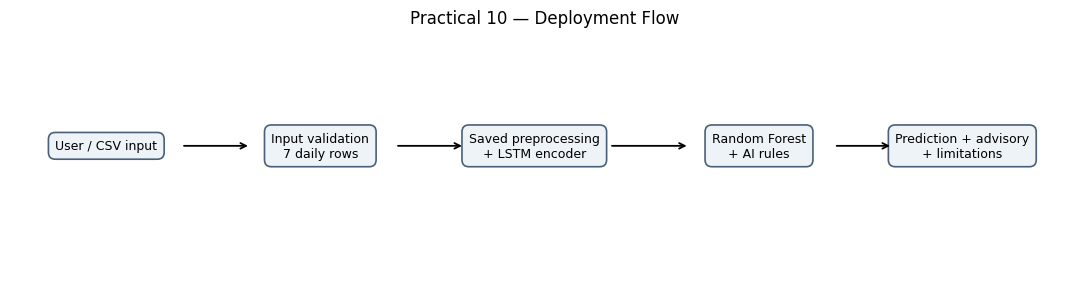

,Deployment check,Status
0,Saved LSTM weights exist,PASS
1,Saved ML/preprocessing bundle exists,PASS
2,Feature metadata and thresholds exist,PASS
3,Streamlit app source exists,PASS
4,Inference core exists,PASS
5,Environment requirements documented,PASS
6,External operational validation,NOT DONE


To launch locally: pip install -r requirements.txt  &&  streamlit run app.py


In [8]:
fig, ax = plt.subplots(figsize=(11, 3.0))
ax.axis("off")
labels = ["User / CSV input", "Input validation\n7 daily rows", "Saved preprocessing\n+ LSTM encoder", "Random Forest\n+ AI rules", "Prediction + advisory\n+ limitations"]
xs = [0.02, 0.22, 0.42, 0.63, 0.82]
for x, label in zip(xs, labels):
    ax.text(x+0.07, 0.55, label, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.55", fc="#eef3f8", ec="#4a6078", lw=1.2), transform=ax.transAxes)
for i in range(len(xs)-1):
    ax.annotate("", xy=(xs[i+1]+0.005,0.55), xytext=(xs[i]+0.14,0.55), xycoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->", lw=1.3))
ax.set_title("Practical 10 — Deployment Flow", pad=10)
fig.tight_layout(); fig.savefig(RESULT_DIR / "task10_deployment_flow.png", dpi=160); plt.show()

readiness = pd.DataFrame([
    {"Deployment check":"Saved LSTM weights exist", "Status":"PASS" if (ARTIFACT_DIR/"task9_lstm_encoder_state_dict.pt").exists() else "FAIL"},
    {"Deployment check":"Saved ML/preprocessing bundle exists", "Status":"PASS" if (ARTIFACT_DIR/"task9_ml_and_preprocessing.joblib").exists() else "FAIL"},
    {"Deployment check":"Feature metadata and thresholds exist", "Status":"PASS" if (ARTIFACT_DIR/"task9_system_metadata.json").exists() else "FAIL"},
    {"Deployment check":"Streamlit app source exists", "Status":"PASS" if (ROOT/"app.py").exists() else "FAIL"},
    {"Deployment check":"Inference core exists", "Status":"PASS" if (ROOT/"system_core.py").exists() else "FAIL"},
    {"Deployment check":"Environment requirements documented", "Status":"PASS" if (ROOT/"requirements.txt").exists() else "FAIL"},
    {"Deployment check":"External operational validation", "Status":"NOT DONE"},
])
display(readiness)
readiness.to_csv(RESULT_DIR / "task10_deployment_readiness.csv", index=False)
print("To launch locally: pip install -r requirements.txt  &&  streamlit run app.py")

## 9. Export practical evidence

The following files are saved to `practical10_results/`: test metrics, confusion matrix, misclassified cases, advisory distribution, input validation tests, water-area diagnostic, responsible-AI checks, deployment flow, and readiness checklist.

In [9]:
summary = {
    "practical": "10 — Validation, Evaluation and Deployment Readiness",
    "test_rows": int(len(predictions)),
    "test_accuracy": float(accuracy_score(actual, predicted)),
    "test_flood_recall": float(recall_score(actual, predicted, zero_division=0)),
    "false_positives": int(((actual==0)&(predicted==1)).sum()),
    "false_negatives": int(((actual==1)&(predicted==0)).sum()),
    "valid_inference_repeat_difference": float(probability_difference),
    "input_validation_tests_passed": int((input_tests["Result"]=="PASS").sum()),
    "input_validation_tests_total": int(len(input_tests)),
    "task_type": "same-day classification using a seven-day window; not next-day forecasting",
    "operational_warning": "Educational prototype only; not validated for public flood warnings."
}
(RESULT_DIR/"task10_run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))
print("\nGenerated evidence files:")
for path in sorted(RESULT_DIR.iterdir()):
    if path.is_file(): print(f"{path.name:45s} {path.stat().st_size:>9,d} bytes")

{
  "practical": "10 \u2014 Validation, Evaluation and Deployment Readiness",
  "test_rows": 204,
  "test_accuracy": 0.8970588235294118,
  "test_flood_recall": 0.8333333333333334,
  "false_positives": 8,
  "false_negatives": 13,
  "valid_inference_repeat_difference": 1.1102230246251565e-16,
  "input_validation_tests_passed": 6,
  "input_validation_tests_total": 6,
  "task_type": "same-day classification using a seven-day window; not next-day forecasting",
  "operational_warning": "Educational prototype only; not validated for public flood warnings."
}

Generated evidence files:
task10_advisory_counts.csv                           77 bytes
task10_advisory_distribution.png                 47,767 bytes
task10_confusion_matrix.png                      31,028 bytes
task10_deployment_flow.png                       41,843 bytes
task10_deployment_readiness.csv                     281 bytes
task10_input_validation_tests.csv                   664 bytes
task10_integrated_test_metrics.csv         